# Lab 04: Data Formats: XML and JSON

*INFO 4617/5617 · Week 4 · Chapter 4, [Data Formats: XML and JSON](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-04-data-formats.html)*

Today we code together. Each step below says what we're building and why, and its code cell holds only the comments that frame it: we write the code live, in class. Nothing here is turned in. After each step, a **💬 Discuss** box holds questions to talk over before the next one; click it to open it. The **⏱ Microsprints** are short tasks for you alone or with a neighbor, each ending in something to share with the room.

We'll parse one real source in each format. **XML:** the roster of the U.S. House of Representatives that the Office of the Clerk publishes, the chapter's case. We'll walk its tree, count its parties, read what the count hides, and turn it into a DataFrame. **JSON:** a year of daily weather for Boulder from NASA's POWER API, which we'll take apart one key at a time, turn into a DataFrame, and plot. The chapter's JSON case, the Open-Meteo forecast, is yours in the Recommended Exercises.

**Before class:** open this notebook in the `webdata` environment (chapter 1), and have your email address ready for the User-Agent. Nothing today needs a key or an account.

On Friday, run every cell above where we stopped (**Run → Run All Above Selected Cell**).

> **Instructor key.** Every cell is filled in and was run against the live sites on 2026-10-21; every cell ran live. The weather is for the whole of 2025, a fixed past year, so Steps 6–8 will match a rerun. The House roster has no fixed date: this run read the copy published October 1, 2026, and a rerun after the Clerk's next update can change the counts in Steps 1–4 as members resign and seats are filled. The lab follows the textbook at commit d9306b7.

## Step 0 — Set up (4 minutes)

Import what today needs: `requests` to fetch, [BeautifulSoup](https://www.crummy.com/software/BeautifulSoup/bs4/doc/#parsing-xml) to parse XML, Python's built-in [`json`](https://docs.python.org/3/library/json.html) module for JSON strings, `Counter` to tally, `time` to pause between requests, pandas, and matplotlib. Then define `HEADERS` with the book's User-Agent, as in week 2, and send it with every request. BeautifulSoup's `"xml"` parser comes from the `lxml` package, which the `webdata` environment includes; if Step 2 stops with `bs4.FeatureNotFound`, the chapter's callout in ["Parsing with BeautifulSoup"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-04-data-formats.html#parsing-with-beautifulsoup) says how to add it.

In [1]:
# Import requests, json, time, Counter (from collections), BeautifulSoup (from bs4), pandas as pd, matplotlib.pyplot as plt
# Define HEADERS: a dict whose "User-Agent" is "WebDataScience/1.0 (your-email@colorado.edu)", with your email
import json
import time
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import requests
from bs4 import BeautifulSoup

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
print(HEADERS)

{'User-Agent': 'WebDataScience/1.0 (your-email@colorado.edu)'}


<details>
<summary>💬 Discuss</summary>

- In week 2 we wrote this User-Agent. Who reads it, and what can they do with the email address in it?
- Neither site we use today refuses a request without one. Why send it anyway?

</details>

## Step 1 — Fetch the roster, and look before you parse (6 minutes)

The Clerk publishes the roster at `https://clerk.house.gov/xml/lists/MemberData.xml`. Open that address in Chrome first: a file with no stylesheet is drawn as a tree you can fold, as in the chapter's figure of it. Then fetch it with `requests.get()`, as the chapter does. Before parsing anything, look at three things: the status code, the `Content-Type` header, and the first bytes of [`response.content`](https://requests.readthedocs.io/en/stable/api/#requests.Response.content), the body as the server sent it. The header names no character set, so `requests` guesses one, [`response.encoding`](https://requests.readthedocs.io/en/stable/api/#requests.Response.encoding): compare its guess with the encoding the file declares in its first line. The chapter's ["Working with Real XML"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-04-data-formats.html#working-with-real-xml) explains why this matters.

In [2]:
# Define ROSTER, the roster's address, and fetch it with HEADERS
# Print the status code, the Content-Type header, the size in bytes, and the encoding requests guessed
# Print the first 150 bytes of response.content: which encoding does the file itself declare?
ROSTER = "https://clerk.house.gov/xml/lists/MemberData.xml"
response = requests.get(ROSTER, headers=HEADERS)
print(response.status_code, response.headers["Content-Type"])
print(f"{len(response.content):,} bytes; requests guessed {response.encoding}")
print(response.content[:150])

200 text/xml
557,203 bytes; requests guessed ISO-8859-1
b'<?xml version="1.0" encoding="UTF-8"?><MemberData publish-date="October 1, 2026"><title-info><congress-num>119</congress-num><congress-text>One Hundre'


<details>
<summary>💬 Discuss</summary>

- `clerk.house.gov/robots.txt` answers 404. What did week 2 say a missing `robots.txt` means, and what doesn't it mean?
- Our code assumes the Clerk answers. If it sent a 503 and an HTML error page instead, which line today would stop, or would we just find zero members? What would you print first to tell?
- Your Recommended Exercises start the same way with an RSS feed. What would you check here before writing any parsing code?

</details>

## Step 2 — Walk the tree: `find`, `find_all`, text, and attributes (10 minutes)

`BeautifulSoup(response.content, "xml")` turns the bytes into a tree; hand it the bytes, not `response.text`, so that it reads the encoding the file declares. There are two ways down the tree. Dot notation (`soup.members.member`) takes the first tag of that name, and works only for names that are Python identifiers. [`.find()`](https://www.crummy.com/software/BeautifulSoup/bs4/doc/#find) and [`.find_all()`](https://www.crummy.com/software/BeautifulSoup/bs4/doc/#find-all) search the whole subtree, so they reach `<firstname>` inside `<member-info>` and work for hyphenated names like `<state-fullname>`. A tag's `.contents` lists its direct children. Text sits between tags and is read with `.text`; attributes sit inside the opening tag and are read with brackets, like a dictionary. The root's `publish-date` attribute says which snapshot of the House this is. See the chapter's ["Parsing with BeautifulSoup"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-04-data-formats.html#parsing-with-beautifulsoup).

In [3]:
# Parse response.content with the "xml" parser; print the root MemberData tag's publish-date attribute and its children's names
# Take the first member with dot notation and print its statedistrict; with .find(), its lastname and party (text),
#   its state's postal-code (an attribute), and its state-fullname
# find_all the member tags into members, and print how many there are
soup = BeautifulSoup(response.content, "xml")
print(soup.MemberData["publish-date"])
print([child.name for child in soup.MemberData.contents])
first = soup.members.member
print(first.statedistrict.text, first.find("lastname").text, first.find("party").text)
print(first.find("state")["postal-code"], first.find("state-fullname").text)
members = soup.find_all("member")
print(f"Total members found: {len(members)}")

October 1, 2026
['title-info', 'members', 'committees']
AK00 Begich R
AK Alaska
Total members found: 441


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** the chapter says that parsing `response.text` would garble accented names. Check it: parse [`response.text`](https://requests.readthedocs.io/en/stable/api/#requests.Response.text) into a second tree, and compare its last names with ours, member by member.
**Share:** how many last names differ between the two trees, and one as each tree spells it.

In [4]:
# Microsprint: parse response.text into a second tree, garbled; make a list of last names from each tree
# Pair the two lists with zip(), and print each pair that differs
garbled = BeautifulSoup(response.text, "xml")
ours = [m.find("lastname").text for m in members]
theirs = [m.find("lastname").text for m in garbled.find_all("member")]
for a, b in zip(ours, theirs):
    if a != b:
        print(f"{a} -> {b}")

Sánchez -> SÃ¡nchez
Barragán -> BarragÃ¡n
García -> GarcÃ­a
Velázquez -> VelÃ¡zquez
Hernández -> HernÃ¡ndez


<details>
<summary>💬 Discuss</summary>

- Why does `soup.member-info` fail? What does Python think you wrote?
- The second tree parsed without an error or a warning. How would you have noticed the garbled names, and in which week 1 attribute of the response was the clue?
- The roster keeps the state's postal code in an attribute and its full name in a child tag. If you designed the file, which would you choose, and why?

</details>

## Step 3 — Count, then read the count (8 minutes)

[`Counter`](https://docs.python.org/3/library/collections.html#collections.Counter) tallies a list. Collect every member's `<party>` text and count them. Then read the odd entries instead of discarding them. An empty party is a vacant seat: its `<member>` block is still there with every tag empty, and a `<footnote>` says why. And the schema records two things about each member, `<party>` (formal registration) and `<caucus>` (the party they sit with), which don't always agree. See the end of the chapter's ["Working with Real XML"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-04-data-formats.html#working-with-real-xml).

In [5]:
# Count the members' party text with Counter
# For each member whose party is empty, print its statedistrict and its footnote
# Count (party, caucus) pairs with Counter: which pair doesn't match?
parties = [m.find("party").text for m in members]
print(Counter(parties))
for m in members:
    if m.find("party").text == "":
        print(m.find("statedistrict").text, "|", m.find("footnote").text)
pairs = [(m.find("party").text, m.find("caucus").text) for m in members]
print(Counter(pairs))

Counter({'R': 221, 'D': 217, '': 2, 'I': 1})
FL20 | Vacancy due to the resignation of Sheila Cherfilus-McCormick, April 21, 2026.
TX23 | Vacancy due to the resignation of Tony Gonzales, April 14, 2026.
Counter({('R', 'R'): 221, ('D', 'D'): 217, ('', ''): 2, ('I', 'R'): 1})


<details>
<summary>💬 Discuss</summary>

- The roster has 441 entries. How many representatives are serving, and what would a paper that reported 441 have gotten wrong?
- One member's party is `I` and his caucus is `R`. Name a research question for which he counts as a Republican, and one for which he doesn't.
- Week 3 said to record the date with every collection, because one run is a snapshot. What does `publish-date` let a reader of your analysis do that the counts alone don't?

</details>

## Step 4 — From XML to a DataFrame (10 minutes)

The chapter's pipeline: `find_all()` the records, pull the fields you need out of each one into a dictionary, collect the dictionaries in a list, and pass the list to [`pd.DataFrame()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html). The state comes from the `postal-code` attribute, not from text. Then count the rows per state with [`groupby()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html). This is the chapter's code from ["From XML to DataFrame"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-04-data-formats.html#from-xml-to-dataframe), with one change: the chapter guards each field with `if m.find(...) else None`, in case a tag is missing, and we leave the guards out to keep the loop short. The Discuss box asks what that costs.

In [6]:
# For each member, build a dict record: first_name, last_name, party, state (the state tag's postal-code attribute),
#   and district; collect the records in a list and make the DataFrame df
# Print df.head() and the 10 states with the most rows
records = []
for m in members:
    record = {"first_name": m.find("firstname").text, "last_name": m.find("lastname").text,
              "party": m.find("party").text, "state": m.find("state")["postal-code"],
              "district": m.find("district").text}
    records.append(record)
df = pd.DataFrame(records)
print(df.head())
print(df.groupby("state").size().sort_values(ascending=False).head(10))

  first_name last_name party state  district
0   Nicholas    Begich     R    AK  At Large
1      Barry     Moore     R    AL       1st
2    Shomari   Figures     D    AL       2nd
3       Mike    Rogers     R    AL       3rd
4     Robert  Aderholt     R    AL       4th
state
CA    52
TX    38
FL    28
NY    26
IL    17
PA    17
OH    15
GA    14
NC    14
MI    13
dtype: int64


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** drop the vacant seats, then make a table of state by party with [`pd.crosstab()`](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html). Count the states whose delegation has at least one Democrat and one Republican, and look up Colorado's row.
**Share:** the number of split states, and Colorado's split.

In [7]:
# Microsprint: keep the rows whose party isn't empty, then pd.crosstab() state by party
# Count the states with at least one D and one R, and print Colorado's row
serving = df[df["party"] != ""]
table = pd.crosstab(serving["state"], serving["party"])
split = table[(table["D"] > 0) & (table["R"] > 0)]
print(f"{len(split)} of {len(table)} states and territories send members of both parties")
print(table.loc["CO"])

29 of 56 states and territories send members of both parties
party
D    4
I    0
R    4
Name: CO, dtype: int64


<details>
<summary>💬 Discuss</summary>

- We left out the chapter's `if m.find(...) else None`. If one member had no `<district>` tag, what would our loop do, and what would the chapter's do?
- The vacancies have every tag, just empty. Would the chapter's guards have caught them? What did?
- In week 1, one call, `pd.DataFrame(data["items"])`, turned the pageviews JSON into a DataFrame. Why did the roster need a loop?

</details>

## Step 5 — JSON is lists and dictionaries (9 minutes)

A JSON array is a Python list, and a JSON object is a Python dictionary. [`json.dumps()`](https://docs.python.org/3/library/json.html#json.dumps) writes Python as a JSON string, and [`json.loads()`](https://docs.python.org/3/library/json.html#json.loads) parses one back (the `s` is for *string*). Take the roster's first two rows as a list of dictionaries with [`to_dict("records")`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_dict.html), write them as JSON, parse the string back, and make a DataFrame again: the list-of-dictionaries pattern runs both ways. See the chapter's "The List-of-Dictionaries Pattern" and "Parsing JSON Strings".

In [8]:
# Take df's first two rows as a list of dicts (to_dict("records")) and print them as JSON (json.dumps, indent=2)
# Parse that string back with json.loads; print its type and the first record's last_name, then make it a DataFrame
rows = df.head(2).to_dict("records")
as_json = json.dumps(rows, indent=2)
print(as_json)
back = json.loads(as_json)
print(type(back), back[0]["last_name"])
print(pd.DataFrame(back))

[
  {
    "first_name": "Nicholas",
    "last_name": "Begich",
    "party": "R",
    "state": "AK",
    "district": "At Large"
  },
  {
    "first_name": "Barry",
    "last_name": "Moore",
    "party": "R",
    "state": "AL",
    "district": "1st"
  }
]
<class 'list'> Begich
  first_name last_name party state  district
0   Nicholas    Begich     R    AK  At Large
1      Barry     Moore     R    AL       1st


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** `json.loads()` three broken strings, the kinds the chapter's ["Common Issues to Debug"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-04-data-formats.html#common-issues-to-debug) lists: single quotes, a trailing comma, and an HTML error page where JSON should be. Errors are this microsprint's subject, so it catches them with `try`/`except` to see all three messages in one run.
**Share:** each error message, and which of the three you'd expect from a live API.

In [9]:
# Microsprint: json.loads() each of "{'name': 'Colorado'}", '{"name": "Colorado",}', and "<html><body>Too Many Requests</body></html>",
#   catching json.JSONDecodeError and printing its message
for broken in ["{'name': 'Colorado'}", '{"name": "Colorado",}', "<html><body>Too Many Requests</body></html>"]:
    try:
        json.loads(broken)
    except json.JSONDecodeError as error:
        print(f"{broken!r}: {error}")

"{'name': 'Colorado'}": Expecting property name enclosed in double quotes: line 1 column 2 (char 1)
'{"name": "Colorado",}': Expecting property name enclosed in double quotes: line 1 column 21 (char 20)
'<html><body>Too Many Requests</body></html>': Expecting value: line 1 column 1 (char 0)


<details>
<summary>💬 Discuss</summary>

- Every value in our records is a string, because XML gave us text. In week 1's pageviews JSON, what type was `views`, and who decided?
- If `.json()` fails on a live response, the body is probably an error page. Which two things from week 1's tour of the response would you print first to find out?
- The House publishes its roster as XML, and NASA its weather as JSON. Using the chapter's "When to Use Which", why might each have chosen its format?

</details>

## Step 6 — Peel the onion: a year of Boulder's weather (9 minutes)

NASA's [POWER API](https://power.larc.nasa.gov/docs/services/api/temporal/daily/) serves daily weather for any point on Earth, with no key, from MERRA-2, a model of the atmosphere fitted to observations. Its address is `https://power.larc.nasa.gov/api/temporal/daily/point`. Ask for the chapter's Boulder coordinates and the whole of 2025: daily high (`T2M_MAX`), low (`T2M_MIN`), and precipitation (`PRECTOTCORR`). The parameters go in a dictionary, as in the chapter, and `print(response.url)` shows the full address `requests` built, which you can paste into Chrome with **Pretty-print** ticked. Then peel the onion, as the chapter's ["Handling Deeply Nested JSON"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-04-data-formats.html#handling-deeply-nested-json) does: `type()` and `.keys()` at the top, then one key deeper at a time, until you reach the values. Use [`.get()`](https://docs.python.org/3/library/stdtypes.html#dict.get) for a key that might be missing. A past year gives the same answer every time you ask; a forecast never does.

In [10]:
# Define POWER, the API's address, and params: parameters "T2M_MAX,T2M_MIN,PRECTOTCORR", community "AG", format "JSON",
#   latitude 40.01, longitude -105.27, start "20250101", end "20251231"
# Fetch with params and HEADERS, parse with .json() into data, and print response.url, type(data), and data.keys()
POWER = "https://power.larc.nasa.gov/api/temporal/daily/point"
params = {"parameters": "T2M_MAX,T2M_MIN,PRECTOTCORR", "community": "AG", "format": "JSON",
          "latitude": 40.01, "longitude": -105.27, "start": "20250101", "end": "20251231"}
response = requests.get(POWER, params=params, headers=HEADERS)
data = response.json()
print(response.url)
print(type(data), data.keys())

https://power.larc.nasa.gov/api/temporal/daily/point?parameters=T2M_MAX%2CT2M_MIN%2CPRECTOTCORR&community=AG&format=JSON&latitude=40.01&longitude=-105.27&start=20250101&end=20251231
<class 'dict'> dict_keys(['type', 'geometry', 'properties', 'header', 'messages', 'parameters', 'times'])


In [11]:
# One key deeper at a time: print data["geometry"]["coordinates"], the keys under "properties" and then under
#   "parameter", data["parameters"] (each variable's units), and data.get("messages")
print(data["geometry"]["coordinates"])
print(data["properties"].keys())
print(data["properties"]["parameter"].keys())
print(data["parameters"])
print(data.get("messages"))

[-105.27, 40.01, 1801.15]
dict_keys(['parameter'])
dict_keys(['T2M_MAX', 'T2M_MIN', 'PRECTOTCORR'])
{'T2M_MAX': {'units': 'C', 'longname': 'Temperature at 2 Meters Maximum'}, 'T2M_MIN': {'units': 'C', 'longname': 'Temperature at 2 Meters Minimum'}, 'PRECTOTCORR': {'units': 'mm/day', 'longname': 'Precipitation Corrected'}}
[]


<details>
<summary>💬 Discuss</summary>

- The coordinates came back as `[-105.27, 40.01, 1801.15]`. Which number is the latitude, how would you know, and what is the third?
- POWER's `robots.txt` disallows `/api/` for crawlers, as Wikipedia's disallows `/w/` (week 2). Are we a crawler?
- Our code assumes POWER answers. If it sent a 429 and an HTML page instead, which line would stop first, with which of Step 5's messages? Does the chapter's Open-Meteo code guard against that?

</details>

## Step 7 — Into a DataFrame, and a plot (12 minutes)

`data["properties"]["parameter"]` is a dictionary of dictionaries: one per variable, each keyed by date. `pd.DataFrame()` lines them up by those keys, one column per variable and one row per date. Turn the index into dates with [`pd.to_datetime()`](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html) and `format="%Y%m%d"`, and replace POWER's fill value for a missing day, which `data["header"]` names, with `NaN`. Then plot the highs and lows as the chapter plots its forecast, with [`fill_between()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.fill_between.html) between them. We start the plot with [`plt.subplots()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html), the course's one way to plot; the chapter's `plt.figure()` draws the same thing. The chapter's forecast holds *parallel lists* instead, matched only by position; these values are matched by date.

In [12]:
# Make weather, a DataFrame of data["properties"]["parameter"]; turn its index into dates (format="%Y%m%d"),
#   replace data["header"]["fill_value"] with float("nan"), and rename the columns high, low, and precip
# Print the first rows, the number of days, and the number of missing values in each column
weather = pd.DataFrame(data["properties"]["parameter"])
weather.index = pd.to_datetime(weather.index, format="%Y%m%d")
weather = weather.replace(data["header"]["fill_value"], float("nan"))
weather = weather.rename(columns={"T2M_MAX": "high", "T2M_MIN": "low", "PRECTOTCORR": "precip"})
print(weather.head())
print(f"{len(weather)} days")
print(weather.isna().sum())

            high   low  precip
2025-01-01  4.50 -7.35    0.38
2025-01-02  7.86 -4.40    2.75
2025-01-03  9.47 -2.41    0.08
2025-01-04  3.82 -6.12    0.91
2025-01-05  0.13 -7.76    0.71
365 days
high      0
low       0
precip    0
dtype: int64


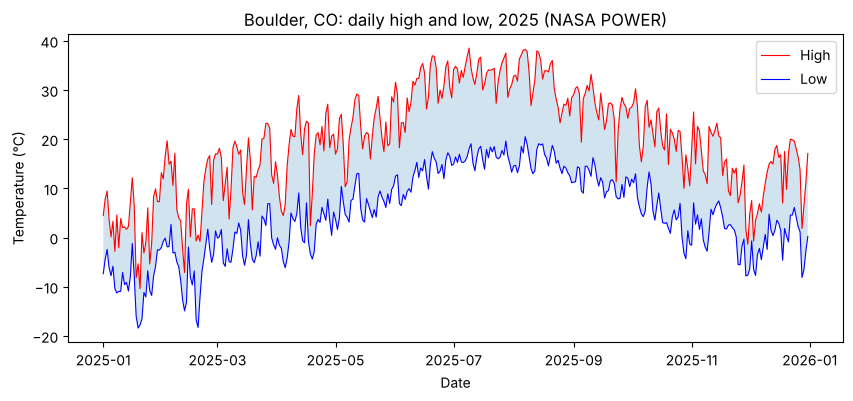

In [13]:
# With fig, ax = plt.subplots(), plot high and low with fill_between between them; add a title, axis labels, and a legend
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weather.index, weather["high"], label="High", color="red", linewidth=0.8)
ax.plot(weather.index, weather["low"], label="Low", color="blue", linewidth=0.8)
ax.fill_between(weather.index, weather["low"], weather["high"], alpha=0.2)
ax.set(title="Boulder, CO: daily high and low, 2025 (NASA POWER)", xlabel="Date", ylabel="Temperature (°C)")
ax.legend()
plt.show()

### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** a short version of Additional Exercise 3, on our year instead of a forecast. Count the nights whose low fell below 0 °C, and find the last one before July and the first one after. If there's time, redraw the lows with a line at 0 °C ([`ax.axhline()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.axhline.html)) and the freezing nights marked.
**Share:** the number of freezing nights, and the dates of the last spring frost and the first autumn frost.

In [14]:
# Microsprint: keep the days whose low was below 0 °C in frost; print how many, the last before July, and the first after June
frost = weather[weather["low"] < 0]
print(f"{len(frost)} nights below freezing")
print(f"Last spring frost: {frost[frost.index.month < 7].index.max().date()}")
print(f"First autumn frost: {frost[frost.index.month >= 7].index.min().date()}")

115 nights below freezing
Last spring frost: 2025-04-20
First autumn frost: 2025-10-28


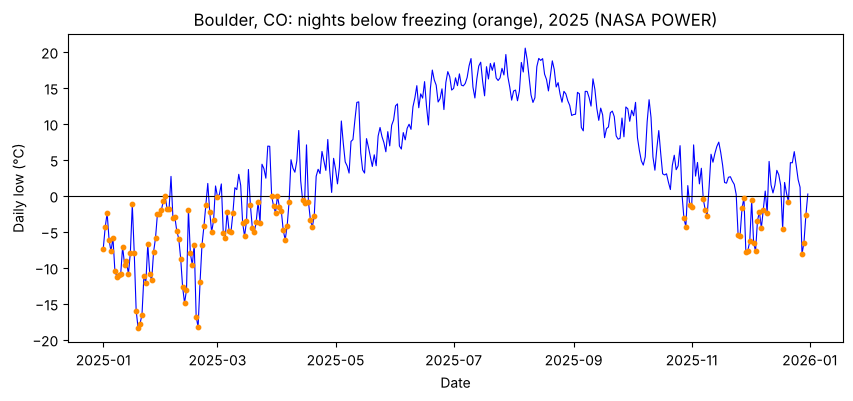

In [15]:
# Microsprint, if there's time: plot the lows, a horizontal line at 0 °C, and the freezing nights as dots, with a title and axis labels
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weather.index, weather["low"], color="blue", linewidth=0.8)
ax.scatter(frost.index, frost["low"], color="darkorange", s=10, zorder=3)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Boulder, CO: nights below freezing (orange), 2025 (NASA POWER)", xlabel="Date", ylabel="Daily low (°C)")
plt.show()

<details>
<summary>💬 Discuss</summary>

- If one day were missing from `T2M_MIN`, what would `pd.DataFrame()` do with it? What if a day were missing from one of the forecast's parallel lists?
- The model's grid cell sits about 150 m above the town, and spans tens of kilometers. Would you write "Boulder had this many freezing nights in 2025"? What would you write instead?

</details>

## Step 8 — One function, more places (12 minutes)

Now we want the same table for more than one place, so this is where a function earns its place. Gather the lines we wrote in Steps 6 and 7 into `get_daily(latitude, longitude, year)`, which returns the DataFrame and the grid cell's elevation; nothing in it is new. Then loop over Boulder and Leadville, at about 3,100 m the highest incorporated city in the United States, and turn each place into one row. The loop pauses a second after each request with [`time.sleep(1)`](https://docs.python.org/3/library/time.html#time.sleep), as [week 2's chapter](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-02-ethics.html#rate-limiting) does. Boulder's row should match Step 7's numbers: that's our check that the function does what the plain lines did.

In [16]:
# Define get_daily(latitude, longitude, year): Step 6's params for that point and year, the request and .json(),
#   then Step 7's DataFrame; return the DataFrame and the elevation (the third coordinate)
def get_daily(latitude, longitude, year):
    params = {"parameters": "T2M_MAX,T2M_MIN,PRECTOTCORR", "community": "AG", "format": "JSON",
              "latitude": latitude, "longitude": longitude, "start": f"{year}0101", "end": f"{year}1231"}
    response = requests.get(POWER, params=params, headers=HEADERS)
    data = response.json()
    weather = pd.DataFrame(data["properties"]["parameter"])
    weather.index = pd.to_datetime(weather.index, format="%Y%m%d")
    weather = weather.replace(data["header"]["fill_value"], float("nan"))
    weather = weather.rename(columns={"T2M_MAX": "high", "T2M_MIN": "low", "PRECTOTCORR": "precip"})
    return weather, data["geometry"]["coordinates"][2]

In [17]:
# For each of places, get_daily() for 2025 and append a dict to rows: place, grid elevation, mean high, and nights below 0 °C
# Sleep a second after each request; then print rows as a DataFrame
places = [("Boulder", 40.01, -105.27), ("Leadville", 39.25, -106.29)]
rows = []
for place, latitude, longitude in places:
    daily, elevation = get_daily(latitude, longitude, 2025)
    rows.append({"place": place, "grid_elevation_m": round(elevation), "mean_high_c": round(daily["high"].mean(), 1),
                 "nights_below_0": int((daily["low"] < 0).sum())})
    time.sleep(1)
print(pd.DataFrame(rows))

       place  grid_elevation_m  mean_high_c  nights_below_0
0    Boulder              1801         19.7             115
1  Leadville              3234          8.1             252


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** call `get_daily()` for a place you know, such as your hometown (its Wikipedia article gives its coordinates; west and south are negative). The key uses Grand Junction, at 39.06, -108.55.
**Share:** your place, its grid elevation, its mean high, and its freezing nights in 2025, beside Boulder's row.

In [18]:
# Microsprint: get_daily() for your place in 2025; print its grid elevation, mean high, and nights below 0 °C
mine, elevation = get_daily(39.06, -108.55, 2025)
print(f"Grid cell at {elevation:.0f} m")
print(f"Mean high: {mine['high'].mean():.1f} °C")
print(f"Nights below 0 °C: {(mine['low'] < 0).sum()}")

Grid cell at 1904 m
Mean high: 18.9 °C
Nights below 0 °C: 122


<details>
<summary>💬 Discuss</summary>

- Leadville's grid cell is about 1,400 m higher than Boulder's. Is the gap in mean highs about what you'd expect, and what else besides height could explain it?
- If each of us looped `get_daily()` over 50 places, how many requests would this room send, and how long would the `sleep` make each loop take (week 2)?
- We wrote `get_daily()` only once we needed it twice. What would you have to change to run the same comparison on the chapter's Open-Meteo forecast, and why couldn't you compare it with these numbers?

</details>

## Step 9 — What did we learn? (5 minutes)

In a few sentences, as comments or in a Markdown cell:

- Of the roster's entries, how many are people serving today? What in the XML told you about the rest, and what would `Counter(parties)` alone have told you?
- How many last names would `response.text` have garbled, and would anything have warned you?
- How many freezing nights did Boulder's grid cell have in 2025, and how do Leadville and your place compare? What does the grid elevation say about what these numbers describe?
- Besides the data, what did each source tell you about itself (`publish-date`, units, `fill_value`)? Which of those would you save beside your DataFrame?

**Recommended Exercises ahead** (in the chapter's companion notebook, due Sunday):

- Step 1, `HEADERS` and an RSS feed you've checked against its `robots.txt`: Step 0's `HEADERS`, and Step 1's question about the Clerk's missing `robots.txt`. [`handouts/week-04/rss-feeds.md`](../../handouts/week-04/rss-feeds.md) lists starter feeds.
- Step 2, fetch the feed and look at the raw XML: Step 1's status code, `Content-Type`, and first bytes.
- Step 3, parse it and count the items: Step 2's `"xml"` parser and `find_all()`.
- Step 4, the items into a DataFrame: Step 4's list-of-dictionaries loop. In a feed the repeating tag is `<item>`.
- Step 5, fetch the forecast and map its keys: Step 6's peeling, one key at a time.
- Step 6, a DataFrame from the forecast's parallel lists, and a plot: Step 7's DataFrame and plot. Parallel lists line up by position, not by date: the chapter's "Handling Deeply Nested JSON" shows how to build a DataFrame from them.
- Step 7, interpret: Steps 3 and 7's Discuss boxes.

In [19]:
# Your answers here, as comments
# The roster published October 1, 2026 has 441 entries and 439 people serving: FL20 and TX23 are vacancies,
#   every tag present and empty, each with a <footnote> giving the resignation. Counter(parties) alone said
#   R 221, D 217, '' 2, I 1: the '' looked like a parsing bug, and the I hid that his <caucus> is R.
# Parsed from response.text, 5 last names came out different (Sánchez became SÃ¡nchez, García
#   became GarcÃ­a). Nothing warned us: the parse succeeded. The clue was in Step 1: the
#   Content-Type names no charset, so requests guessed ISO-8859-1, and the file declares UTF-8.
# Boulder's grid cell had 115 nights below 0 °C in 2025 (last spring frost April 20, first autumn frost
#   October 28), and a mean high of 19.7 °C. Leadville's cell had 252 nights and 8.1 °C. Grand Junction's cell
#   (the key's microsprint: 122 nights, 18.9 °C) sits at 1,904 m, about 500 m above the town, which is likely why it comes out cooler
#   than Boulder: these numbers describe a model's grid cell around a point, not a town's thermometer.
# The roster's publish-date (October 1, 2026); POWER's units (C, mm/day), its fill_value (no day used it:
#   0 missing values), and the cell's elevation. Save the publish-date, the request URL, and the units
#   beside the DataFrame, so a reader knows which snapshot and which grid cell the numbers describe.

## Friday: from the lab to the textbook (15 minutes)

What did the lab turn up that the chapter could say better? Some places to look:

- Step 2 printed the roster's top-level tags. The chapter's "Working with Real XML" names two blocks we ignore, `<title-info>` and each member's `<committee-assignments>`. Is that the whole list, and does the third block hold any tag names that `soup.find()` could pick up by mistake?
- The chapter's printed output says which date the roster was published. What did Step 2 print, and do the chapter's counts still hold?
- Step 4 left out the chapter's `if m.find(...) else None` guards, and every member still parsed, vacancies included. Should the chapter say which tags can be missing in this file, or show a case where a guard matters?
- The chapter fetches the roster and the forecast without `headers=`, though its Recommended Exercises (and week 2) ask for a User-Agent. Should its code send one?
- A microsprint that would make a good Additional Exercise, such as the `response.text` check, the broken JSON, or the freezing nights.
- A sentence in the chapter that confused you before today, and one you could now explain to someone else.

[`handouts/common/revision-framework.md`](../../handouts/common/revision-framework.md) says how to propose a revision.